### Performing LOO-PIT on Field-Level MCMCs with Fixed Initial Conditions

This code book performs LOO-PIT analysis on an MCMC chain provided by Hugo Simon and Arnaud Di Mattia (University of Paris-Saclay). 
The chains are Field-Level inference chains of galaxy density counts over a 32 x 32 x 32 voxel space.
These chains specifically have their initial conditions fixed and only samples over the cosmological parameters. 

First we load the necessary packages

In [1]:
Pkg.instantiate()
Pkg.resolve()

  No Changes to `~/.julia/v1.11/Project.toml`
  No Changes to `~/.julia/v1.11/Manifest.toml`


In [2]:
# Pkg.add("Turing")
# Pkg.add("Capse")
# Pkg.add("NPZ")
# Pkg.add(url="https://github.com/JuliaCosmologicalLikelihoods/PlanckLite.jl")
# Pkg.add("BenchmarkTools")
# Pkg.add("Plots")
# Pkg.add("Optim")
# Pkg.add("ForwardDiff")
# Pkg.add("LinearAlgebra")
# Pkg.add("Pathfinder")
# Pkg.add("MicroCanonicalHMC")
# Pkg.add("Transducers")
# Pkg.add("StatsPlots")
# Pkg.add("PairPlots")
# Pkg.add("LaTeXStrings")
# Pkg.add("MCMCChains")
# Pkg.add("PSIS")
# Pkg.add("ArviZ")
# Pkg.add("ArviZPythonPlots")
# Pkg.add("IrrationalConstants")
# Pkg.add("DimensionalData")
# Pkg.add("Statistics")

In [3]:
# using Turing
# using Capse
using NPZ
# # using PlanckLite
# using BenchmarkTools
# using Plots
# using Optim
# using ForwardDiff
# using Pathfinder
# #using MicroCanonicalHMC
# #using Transducers
# using StatsPlots
# #using PairPlots
# #using LaTeXStrings
# #using CairoMakie
# using MCMCChains
using PSIS
# include("utils.jl");
using ArviZ
using ArviZPythonPlots
using LinearAlgebra
using IrrationalConstants
using DimensionalData
using Statistics
using Plots

### PSIS

We begin by running Pareto Smoothed Importance Sampling (PSIS) on the full voxels, and storing the results.

The chains provided are a single file, which is loaded below. 

In [4]:
f = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/data_hugo/16_mesh_ic/logdf_mesh.npz")

Dict{String, Array{Float64, 5}} with 2 entries:
  "logcdf_mesh" => [-1.23479 -0.801966 … -0.759601 -0.719602; -1.77319 -0.33422…
  "logpdf_mesh" => [-3.73428 -3.591 … -3.58586 -3.58314; -4.03861 -3.74544 … -3…

For the process of PSIS, we need the logpdf_mesh field, which are the log probabilities of each voxel that the chain has determined by fitting the model to the full data set. That is, the logpdf_mesh represent $p(y | \theta)$

In [5]:
f["logpdf_mesh"]

4×512×32×32×32 Array{Float64, 5}:
[:, :, 1, 1, 1] =
 -3.73428  -3.591    -3.604    -3.73748  …  -3.65599  -3.58586  -3.58314
 -4.03861  -3.74544  -3.59216  -3.73022     -3.6853   -3.59686  -3.65763
 -3.75124  -3.61051  -3.69215  -3.59904     -3.58345  -3.65653  -3.58706
 -3.96836  -3.59356  -3.6679   -3.59266     -3.67062  -3.58369  -3.69102

[:, :, 2, 1, 1] =
 -4.08472  -3.63166  -4.08871  -3.58261  …  -3.77289  -3.67531  -3.5838
 -4.15786  -3.60594  -3.66071  -3.70805     -3.59703  -3.70504  -4.22356
 -4.19937  -3.68594  -3.79464  -3.78528     -3.66682  -3.85578  -3.99794
 -3.86839  -3.68389  -3.86989  -3.6924      -3.86385  -3.63095  -3.58263

[:, :, 3, 1, 1] =
 -3.58262  -3.76929  -3.649    -3.65396  …  -3.65903  -3.65248  -3.93204
 -3.59603  -3.98637  -3.59896  -3.74012     -3.87778  -3.58936  -3.58741
 -3.6211   -3.58897  -3.63091  -3.58718     -3.79218  -3.68623  -3.61403
 -3.63404  -3.58765  -3.58542  -3.62308     -3.60893  -3.62673  -3.60024

;;; … 

[:, :, 30, 1, 1] =
 -3.801

Each of the 32 x 32 x 32 voxels has 4 x 512 delta logdensities from the chain corresponding to that voxel.

Below, we create an array of vectors called logpdf_mesh to store the data from the file. Each of the 32 x 32 x 32 elements has a vector corresponding to a single voxel, and the vector holds the log probability values.

In [6]:
logpdf_mesh = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    logpdf_mesh[i,j,k] = []
end

for i in 1:32, j in 1:32, k in 1:32
    append!(logpdf_mesh[i,j,k], vec(f["logpdf_mesh"][:,:,i,j,k]))
end

Thus, log_pdf is a data object representing the 32 x 32 x 32 voxels, with each element holding 2048 log probability values collected from the file.

In [7]:
logpdf_mesh

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [-3.73428, -4.03861, -3.75124, -3.96836, -3.591, -3.74544, -3.61051, -3.59356, -3.604, -3.59216  …  -3.58345, -3.67062, -3.58586, -3.59686, -3.65653, -3.58369, -3.58314, -3.65763, -3.58706, -3.69102]      …  [-3.9245, -3.64141, -3.67802, -3.76399, -3.88006, -4.02435, -3.5911, -4.20753, -3.68653, -3.97887  …  -4.0909, -3.69179, -4.14267, -4.26328, -3.83005, -4.08472, -3.96777, -4.33338, -3.70838, -4.17843]
 [-4.08472, -4.15786, -4.19937, -3.86839, -3.63166, -3.60594, -3.68594, -3.68389, -4.08871, -3.66071  …  -3.66682, -3.86385, -3.67531, -3.70504, -3.85578, -3.63095, -3.5838, -4.22356, -3.99794, -3.58263]      [-3.66998, -3.5852, -3.58923, -3.6692, -3.75245, -3.76982, -3.59456, -3.73264, -3.68222, -3.58582  …  -3.63124, -3.62473, -3.75643, -3.67307, -3.58742, -3.863, -3.85585, -3.58311, -3.62175, -3.73047]
 [-3.58262, -3.59603, -3.6211, -3.63404, -3.76929, -3.98637, -3.58897, -3.58765, -3.649, -3.59896  …  -3.79218, -3.60893, -3.65248, -

In [8]:
logpdf_mesh[3,16,4]

2048-element Vector{Float64}:
 -4.2903935465839504
 -4.4489447043015025
 -4.420852350923282
 -4.510925749646366
 -3.8125391933553887
 -3.7748953202426367
 -4.50022197980358
 -3.789104435057471
 -4.197266668308423
 -5.26852370100042
  ⋮
 -4.520522008813884
 -4.037869744572285
 -4.1636902057666525
 -4.755116963141153
 -4.436110424936907
 -4.596604323032896
 -4.044445855998594
 -4.8421403896077795
 -4.309954107737554

Next, we perform Pareto Smoothed Importance Sampling (PSIS) on each voxel's vector of log pdf probabilities.

In [9]:
psis_result = Array{PSISResult{Float64, Vector{Float64}, Int64, Int64, PSIS.GeneralizedPareto{Float64}}}(undef, 32, 32, 32);
for i in 1:32, j in 1:32, k in 1:32
    psis_result[i, j, k] = psis(-logpdf_mesh[i,j,k])
end

┌ Warning: Pareto shape k = 0.73 > 0.7. Resulting importance sampling estimates are likely to be unstable.
└ @ PSIS /Users/ethansmith/.julia/packages/PSIS/jp3Nb/src/core.jl:365


The importance weights and the pareto shape values are stored in their own 32 x 32 x 32 arrays so that the PSIS weights and the pareto shape value can be recalled easily for each voxel if needed.

In [10]:
psis_weights = Array{Vector{Float64}}(undef, 32, 32, 32)
for i in 1:32, j in 1:32, k in 1:32
    psis_weights[i,j,k] = psis_result[i,j,k].weights
end

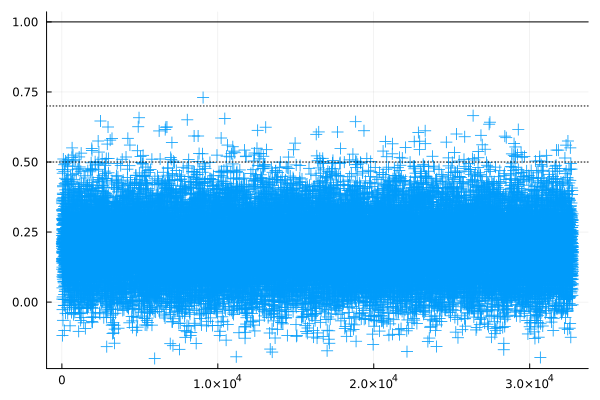

In [11]:
pareto_shapes = []
for i in 1:32, j in 1:32, k in 1:32
    append!(pareto_shapes, psis_result[i,j,k].pareto_shape)
end

psis_plot = Plots.scatter(pareto_shapes; marker =:+, markersize=6, legend = false, linewidth=2)
hline!([0.5,0.7], linestyle=:dot, color =:black)
hline!([1.0], linestyle=:solid, color=:black)

The plot above is of the Pareto shape parameters from PSIS. Because the shape parameters are all under the threshhold of 0.5, this informs that the importance sampling is well-behaved and reliable for probability reweighting in the Leave One Out approach.

Now that we know the weights are reliable, we can proceed with the LOO-PIT analysis. The PSIS weights inform how to reweight $p(y | \theta)$ determined by the MCMC logpdf_mesh field, into $p(y_{-i} | \theta)$, the LOO probability density. 

First load the logcdf_mesh field from the MCMC chain file. Similar to logpdf_mesh, this field has contains 4 x 512 samples corresponding to the CDF of that particular voxel. It is stored below in an array with each voxel having an array of all CDF samples

In [13]:
logcdf_mesh = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    logcdf_mesh[i,j,k] = []
end

for i in 1:32, j in 1:32, k in 1:32
    append!(logcdf_mesh[i,j,k], vec(f["logcdf_mesh"][:,:,i,j,k]))
end

In [14]:
logcdf_mesh

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [-1.23479, -1.77319, -1.27046, -1.66138, -0.801966, -0.334225, -0.899868, -0.581905, -0.872106, -0.809638  …  -0.660931, -1.08648, -0.759601, -0.837101, -1.04898, -0.656658, -0.719602, -1.05197, -0.771305, -0.386743]                     …  [-0.228334, -0.455429, -0.402136, -0.319496, -0.2488, -0.190705, -0.594497, -0.141323, -0.391901, -0.206616  …  -0.170392, -0.38587, -0.156591, -0.129712, -0.275592, -0.172148, -0.210791, -0.116777, -0.368158, -0.147918]
 [-1.84424, -1.95389, -2.01469, -1.49247, -0.975377, -0.535245, -1.12488, -1.11985, -1.85031, -1.06034  …  -1.07658, -1.48444, -1.09847, -1.17004, -1.47009, -0.973083, -0.65483, -2.04971, -1.70903, -0.687521]                                 [-0.41243, -0.752238, -0.789296, -0.413467, -0.328508, -0.315118, -0.577252, -0.345195, -1.11573, -0.631235  …  -0.474123, -0.952409, -0.32535, -0.408396, -0.617872, -0.257438, -0.261206, -0.66803, -0.942094, -0.347125]
 [-0.697814, -0.570803, -0.93

The CDF values are then able to be systemically reweighted by the PSIS weights in order to obtain the LOO-PIT final values.

In [15]:
loo_pit = Array{Float64}(undef, 32, 32, 32)

for i in 1:32
    for j in 1:32
        for k in 1:32
            loo_pit[i,j,k] = dot(psis_weights[i,j,k], exp.(logcdf_mesh[i,j,k]))
        end
    end
end

Plotting the LOO-PIT values in a histogram, we see the approximately uniform distribution of values as expected from a MCMC sampling based on a strong model.

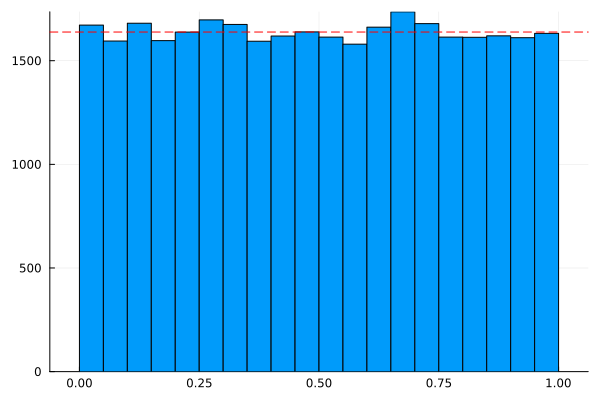

In [16]:
Plots.histogram(vec(loo_pit), legend=false, bins=20)
hline!([length(loo_pit) / 20], color=:red, linestyle=:dash)